# Topic 21c - Change over time

The main lesson built one line with a rolling average. This notebook covers multiple lines on one Axes (one per zone), annotating the single point that matters instead of labelling every point, and a short case for when a rolling average is the wrong tool.

Work through it after reading section 4 of the [main lesson](topic21_data_visualization.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "data_visualization" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Expected a data folder containing the six "
        "Topic 20/21 tables. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette. Hues are assigned in this fixed order to every chart in
# Topic 21 - never cycled, never re-generated - so a category keeps the same
# colour in every chart it appears in. See 21a for why this matters.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"    # de-emphasis grey, for "everything but the finding"
INK = "#0b0b0b"      # text and value labels

# Fixed colour assignment per category, used throughout this topic.
ZONE_COLOR = {"Coastal": PALETTE["blue"], "Middle": PALETTE["aqua"], "Northern": PALETTE["yellow"]}
CHANNEL_COLOR = {"Field Agent": PALETTE["blue"], "Online": PALETTE["aqua"],
                 "Phone": PALETTE["yellow"], "Shop": PALETTE["green"]}
SEGMENT_COLOR = {"Retail": PALETTE["blue"], "Wholesale": PALETTE["aqua"], "Institution": PALETTE["yellow"]}
CATEGORY_COLOR = {
    "Beverages": PALETTE["blue"], "Grains": PALETTE["aqua"], "Cooking Oils": PALETTE["yellow"],
    "Personal Care": PALETTE["green"], "Household": PALETTE["violet"], "Snacks": PALETTE["red"],
    "Canned Goods": PALETTE["magenta"],
}

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/data_visualization/data
files:             ['customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# Paste the function you built in Topic 20. This is the same contract: five
# raw tables in, one analysis-ready table out, with its own row-count check.
def clean_region(series):
    return (series.str.strip()
                  .str.replace(r"\s+", " ", regex=True)
                  .str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)

    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")

    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))

    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)

    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)

    if len(table) != expected_rows:
        raise ValueError(
            f"Row count changed during wrangling: {expected_rows} -> {len(table)}. "
            "A merge has duplicated rows."
        )
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")
targets_wide = pd.read_csv(DATA_DIR / "monthly_targets_wide.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")
print(f"Total revenue: GHS {analysis['revenue_ghs'].sum():,.2f}")
print(f"Total profit:  GHS {analysis['profit_ghs'].sum():,.2f}")

Analysis table: 1200 rows x 24 columns
Total revenue: GHS 230,001.08
Total profit:  GHS 65,886.38


---

## Multiple lines: one series per zone

The main lesson's "revenue rose in Nov-Dec" finding was true for the business as a whole. Splitting the same line by zone tests whether that is true everywhere, or driven by one zone alone.

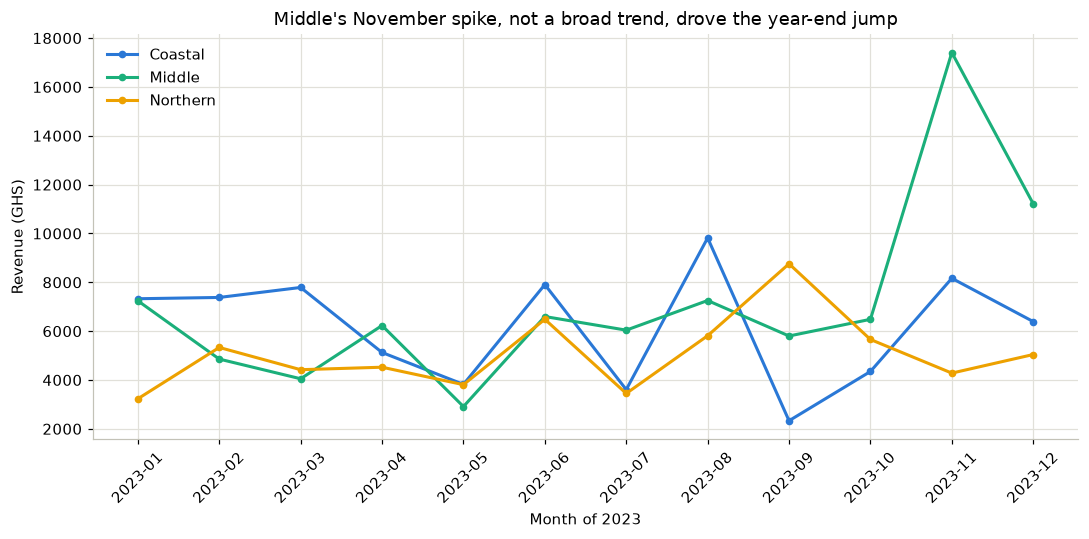

Peak month per zone:
zone
Coastal     2023-08
Middle      2023-11
Northern    2023-09


In [3]:
analysis["period"] = analysis["order_date"].dt.to_period("M").astype(str)
by_zone = analysis.groupby(["period", "zone"])["revenue_ghs"].sum().unstack()
zone_order = ["Coastal", "Middle", "Northern"]
by_zone = by_zone[zone_order]

fig, ax = plt.subplots(figsize=(10, 5))
for zone in zone_order:
    ax.plot(by_zone.index, by_zone[zone], marker="o", markersize=4,
             linewidth=2, label=zone, color=ZONE_COLOR[zone])

ax.set_title("Middle's November spike, not a broad trend, drove the year-end jump")
ax.set_xlabel("Month of 2023")
ax.set_ylabel("Revenue (GHS)")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

print("Peak month per zone:")
print(by_zone.idxmax().to_string())

That is the opposite of what the single-line chart in the main lesson implied. "Revenue rose in Nov-Dec" was true, but reading it as "the business had a strong finish" overstates it - Coastal and Northern had ordinary months in November, and Middle alone jumped from an October figure near GHS 6,500 to over GHS 17,400. A single aggregate line can genuinely hide which part of the business a finding belongs to. This is also why the course colour for each zone stays fixed across every chart in this topic (`ZONE_COLOR`, defined once in the setup cell) - a reader who learned "Middle is the aqua line" here should not have to relearn it in the next chart.

---

## Direct labels instead of a cluttered legend

With three lines a legend box is fine. With more series than that, labelling the **end of each line** directly - instead of making a reader's eye jump between a line and a legend box - reads faster, and it is the "selective direct label" the chart-selection rule in the main lesson referred to.

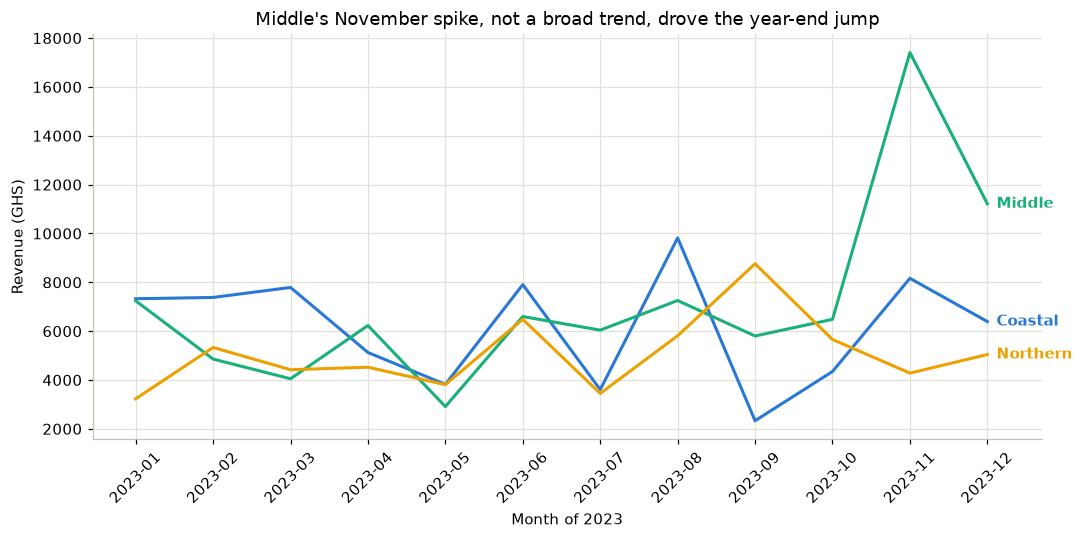

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for zone in zone_order:
    ax.plot(by_zone.index, by_zone[zone], linewidth=2, color=ZONE_COLOR[zone])
    ax.annotate(zone, xy=(len(by_zone) - 1, by_zone[zone].iloc[-1]),
                xytext=(6, 0), textcoords="offset points",
                va="center", color=ZONE_COLOR[zone], fontweight="bold")

ax.set_title("Middle's November spike, not a broad trend, drove the year-end jump")
ax.set_xlabel("Month of 2023")
ax.set_ylabel("Revenue (GHS)")
ax.tick_params(axis="x", rotation=45)
ax.set_xlim(right=len(by_zone) - 0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Note `ax.set_xlim(right=...)` - without extra room on the right, the direct labels collide with the plot's edge. This is a real trade-off: direct labels need that spare margin, and a legend does not. Neither is unconditionally better; pick based on how many series you have and how much horizontal room the figure can spare.

---

## When a rolling average is the wrong tool

A 3-month rolling average smooths monthly noise because there is enough history (12 months) for a 3-point window to still mean something. It stops being useful on a short series - averaging 3 of only 4 available data points barely smooths anything, and it drops the first two points from the chart entirely (there is no full window yet to average).

In [5]:
q1_2023 = analysis[analysis["order_date"] < "2023-04-01"]
weekly = q1_2023.groupby(q1_2023["order_date"].dt.to_period("W"))["revenue_ghs"].sum()
print(f"Only {len(weekly)} weekly data points in Q1 alone - a 3-month rolling average has nothing to work with here.")
print("For a short series, a shorter window (or no smoothing at all) is the honest choice.")

Only 14 weekly data points in Q1 alone - a 3-month rolling average has nothing to work with here.
For a short series, a shorter window (or no smoothing at all) is the honest choice.


### Try It 3 - index two series to a common base

Plot monthly revenue for Coastal and Middle **indexed to January = 100** (divide every month by its January value and multiply by 100), on the same Axes, one line each. This is the "common base" fix the main lesson mentioned for comparing two series of different sizes on one axis, instead of a dual-axis chart. Which zone grew faster, relative to its own January?

In [6]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic21_data_visualization.ipynb)
- Previous: [21b - Comparing categories](topic21b_comparing_categories.ipynb)
- Next: [21d - Distributions](topic21d_distributions.ipynb)